# Moneyball 2.0 для Brentford: от данных FIFA к трансферному решению

**Сценарий 3 (Moneyball 2.0), уровень 3 DSS.** ЛПР — спортивный директор Brentford. Момент решения — начало сезона 2022/23 (снимок FIFA 23, сентябрь 2022).

**Вопрос:** кого купить на ~€60M и €200k/нед зарплат, чтобы сильнее всего закрыть слабые позиции, не переплатить и не купить игрока, который через год сдаст?

Ноутбук показывает ход анализа. Тяжёлые вычисления выполняет `python run_pipeline.py` (~50 с), а ноутбук читает его результаты из `outputs/`. Несколько проверок «ловушек» считаются здесь заново.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd()))
from src import config as C
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
OUT, FIG = C.OUT, C.FIG
img = lambda n: display(Image(filename=str(FIG / n), width=820))
m = json.load(open(OUT / "metrics.json"))

## 1. Данные и их качество
Источник: Kaggle `stefanoleone992/fifa-23-complete-player-dataset`, файл *male_players (legacy).csv*. В нём 161 583 строки «игрок × версия FIFA 15–23» и 110 столбцов.

Одна и та же модель игрока прослеживается через 9 лет. Поэтому можно учиться на реальных изменениях рейтинга N → N+1.

In [2]:
q = m["quality"]
pd.Series({k: v for k, v in q.items() if k != "by_version"}, name="значение").to_frame()

,значение
rows_raw,161583.000000
duplicates_player_version,0.000000
missing_value_or_club,2065.000000
league_name_clashes,12877.000000
club_name_clashes,102.000000
unknown_position,0.000000
missing_attrs_cells,32242.000000
value_skew,8.504224
rows_clean,159518.000000


**Что сделано при очистке (`src/data.py`):**
* удалены строки без клуба или оценки (2 065);
* пропуски атрибутов заполнены медианой по версии × позиции;
* выведены позиционная группа, срок контракта и `log(value)`;
* **разведены одноимённые лиги** (см. ловушку 3).

## 2. Аудит Brentford: стиль и потребности

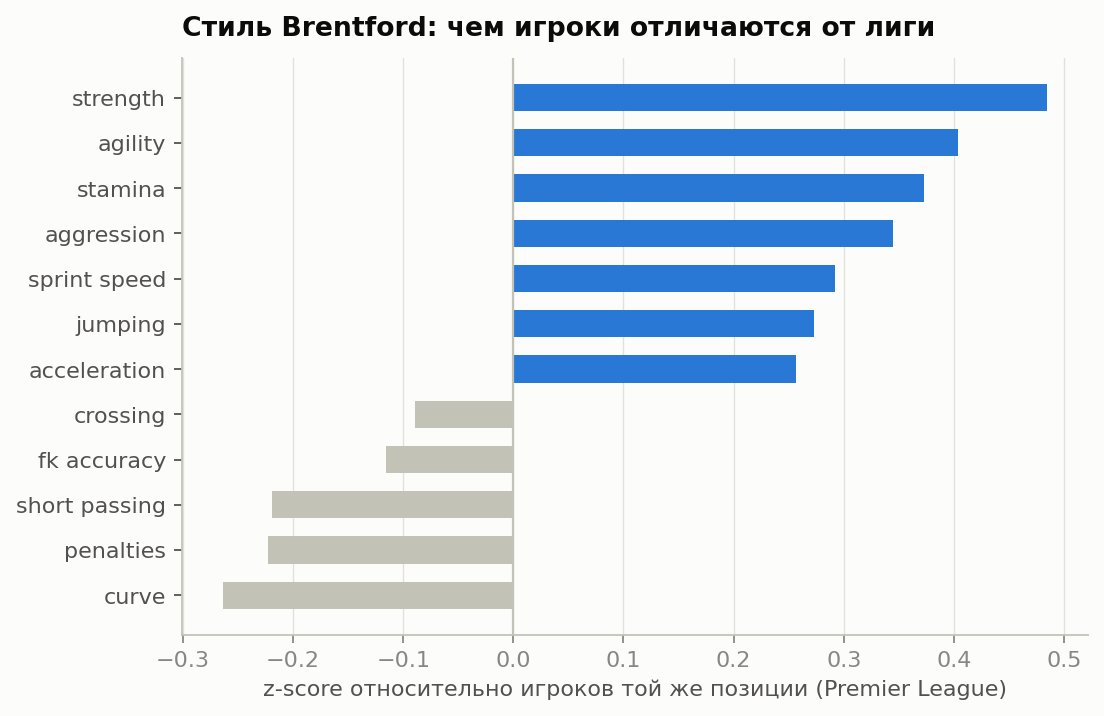

In [3]:
img("01_style_profile.png")

Стиль считается data-driven: топ-18 игроков клуба по минутам/рейтингу, атрибуты переводятся в z-оценки внутри позиции против всех клубов АПЛ.

Брентфорд — **сила, ловкость, выносливость, агрессия**. Эти отклонения сдвигают экспертные веса ролей, то есть «под кого покупаем».

In [4]:
need = pd.read_csv(OUT / "needs.csv")
need[["name", "club_start", "league_rank", "target", "gap", "depth_drop", "league_depth_drop"]].round(2)

,name,club_start,league_rank,target,gap,depth_drop,league_depth_drop
0,Опорный полузащитник,76.28,13,83.83,7.56,2.85,3.15
1,Вратарь,77.89,18,85.30,7.41,0.44,6.60
2,Центральный полузащитник,74.17,20,81.35,7.17,1.20,3.39
3,Нападающий,77.87,14,83.19,5.32,16.01,2.62
4,Крайний защитник,74.99,17,79.09,4.10,6.58,2.57
5,Вингер,75.28,18,79.26,3.98,0.62,2.66
6,Центральный защитник,76.77,16,80.49,3.72,2.28,2.49


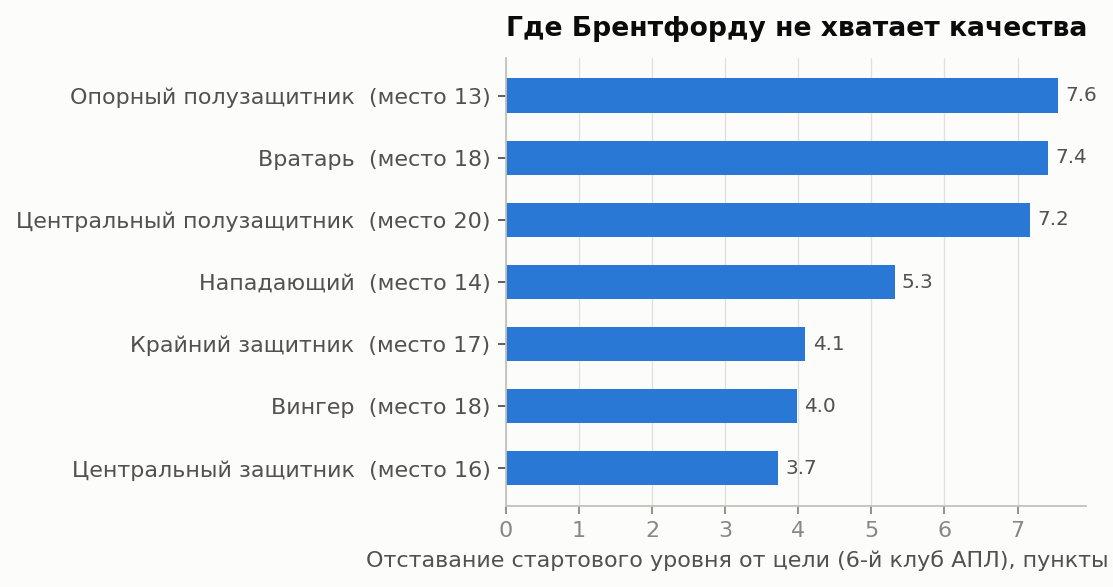

In [5]:
img("02_needs.png")

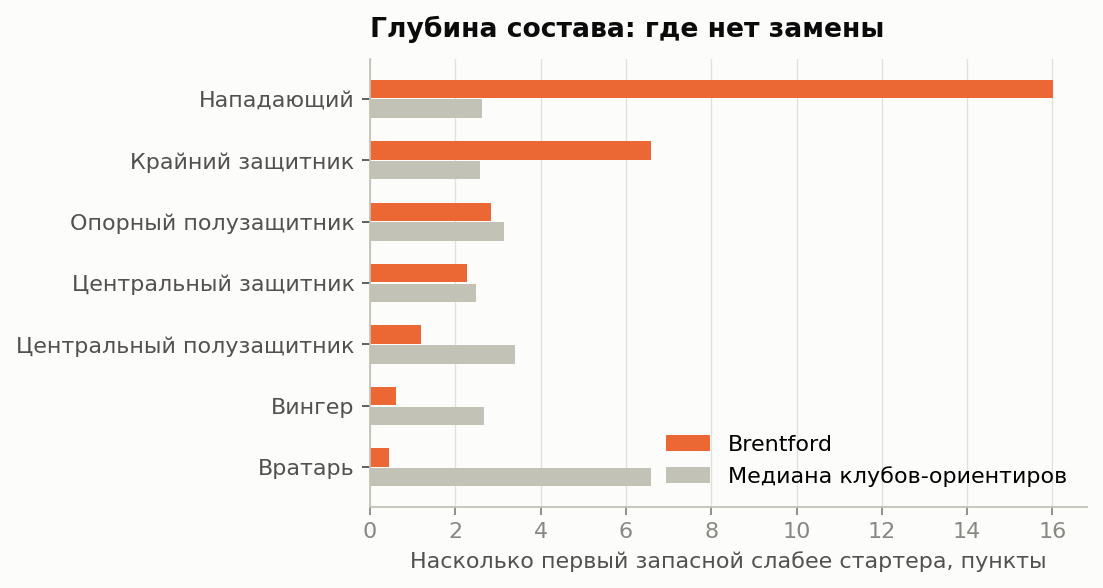

In [6]:
img("03_depth.png")

**Потребности.** Сравниваем уровень стартового игрока с 6-м клубом АПЛ (цель — верхняя половина таблицы).

* По отставанию от 6-го клуба: **DM, GK, CM**.
* Отдельно **глубина**: у Тони (ST) нет дублёра. Падение уровня при замене −16 пунктов против медианы лиги −2.6. Похожая проблема у FB.

Поэтому в оптимизатор попадают 5 позиций.

## 3. Модель развития игрока (FIFA N → N+1)
Целевая переменная — Δoverall через год. Валидация **по времени**, без утечки:

| Выборка | Пары версий |
|---|---|
| train | ≤ 20→21 |
| val | 21→22 |
| test | 22→23 |

In [7]:
pd.read_csv(OUT / 'growth_metrics.csv', index_col=0).round(3)

,MAE,RMSE,R2,Spearman
Без изменений (Δ=0),1.698,2.531,-0.085,NaN
Среднее по возрасту,1.710,2.238,0.152,0.407
Ridge (линейная),1.650,2.160,0.209,0.449
Gradient Boosting,1.607,2.130,0.232,0.482


In [8]:
pd.Series(m['growth']['classification']).round(3).to_frame('риск спада (Δ ≤ −2)')

,риск спада (Δ ≤ −2)
base_rate,0.133
AUC: только возраст,0.717
AUC: Gradient Boosting,0.767


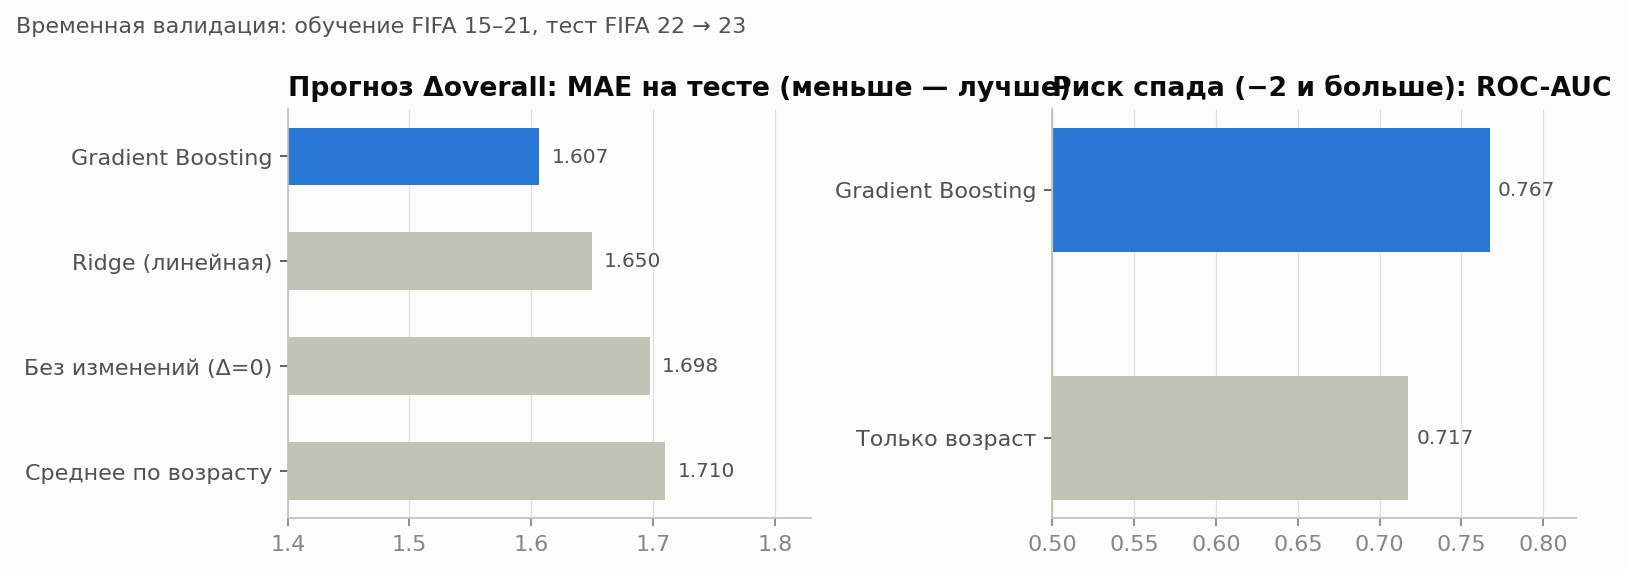

In [9]:
img("04_growth_metrics.png")

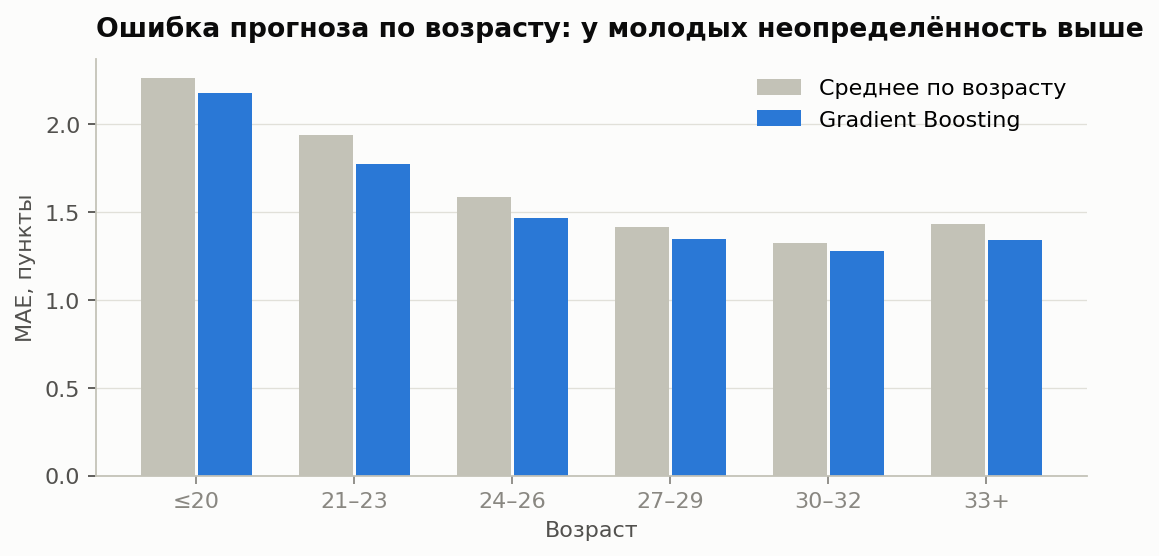

In [10]:
img("05_growth_by_age.png")

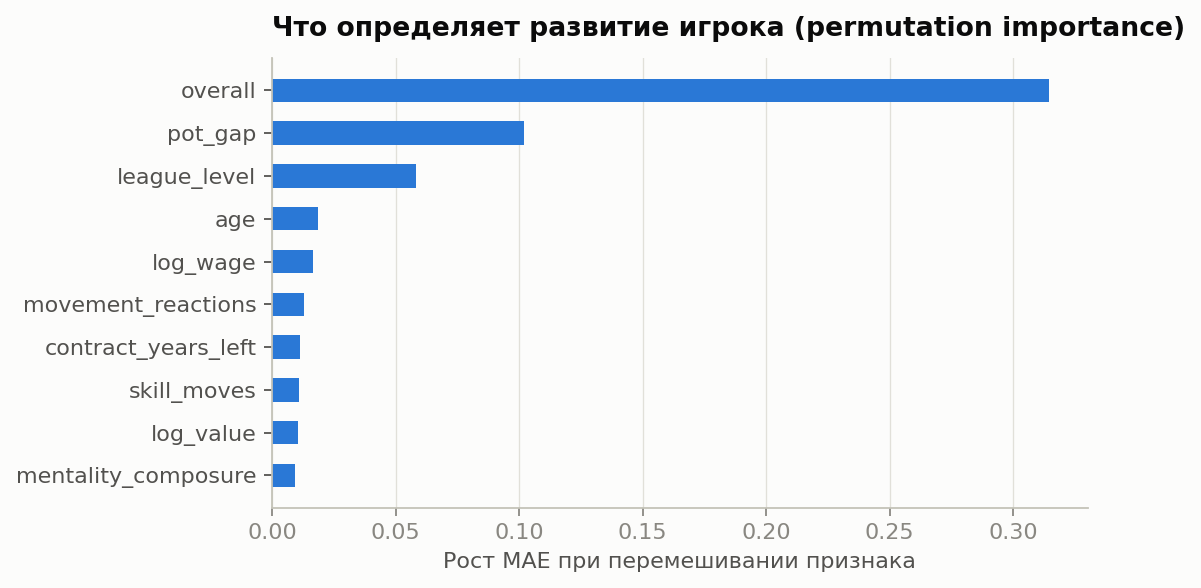

In [11]:
img("06_growth_importance.png")

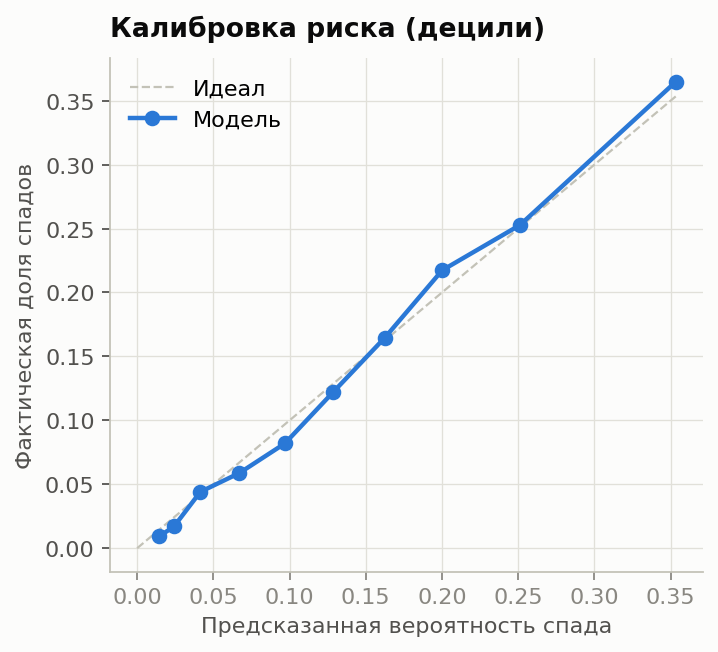

In [12]:
img("07_risk_calibration.png")

**Вывод.**
* Gradient Boosting снижает MAE с 1.70 (Δ=0) до 1.61, Spearman 0.48. Улучшение честное, но скромное: развитие игрока во многом случайно.
* Классификатор спада даёт AUC 0.77 против 0.72 у «только возраста» и хорошо откалиброван.
* 80%-интервал покрывает 79.3% случаев.

Мы используем модель для **ранжирования риска**, а не как точный прогноз.

## 4. Цена: оценка FIFA — это формула (ловушка 4)

In [13]:
pd.read_csv(OUT / 'value_metrics.csv', index_col=0).round(3)

,R2 (log),"Медиана ошибки, %"
Линейная: только overall,0.784,34.063
Линейная: все признаки,0.967,12.318
Gradient Boosting,0.999,1.452


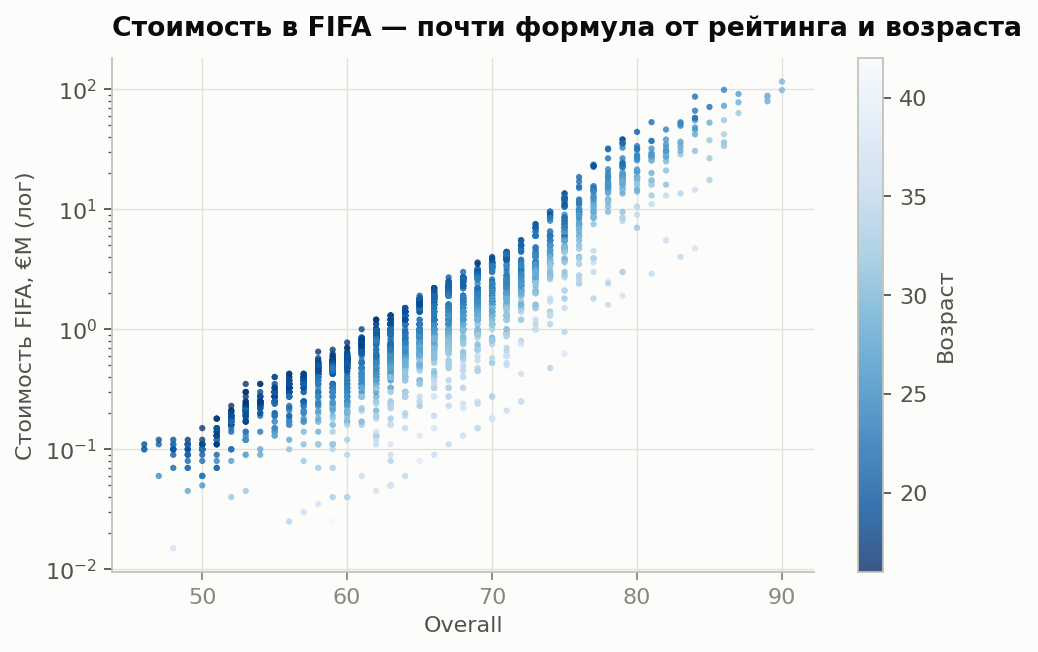

In [14]:
img("08_value_formula.png")

Gradient Boosting восстанавливает `value_eur` с R² = 0.999 и медианной ошибкой 1.5%. Значит, это **детерминированная формула EA**, а не рыночная цена.

Как мы её используем:
* как *относительную* шкалу с премией АПЛ ×1.3;
* для прогноза перепродажи через изменение рейтинга;
* но **не** как «справедливую цену» и **не** для поиска недооценённых по остатку модели — остаток там почти нулевой.

## 5. Стили и похожие игроки

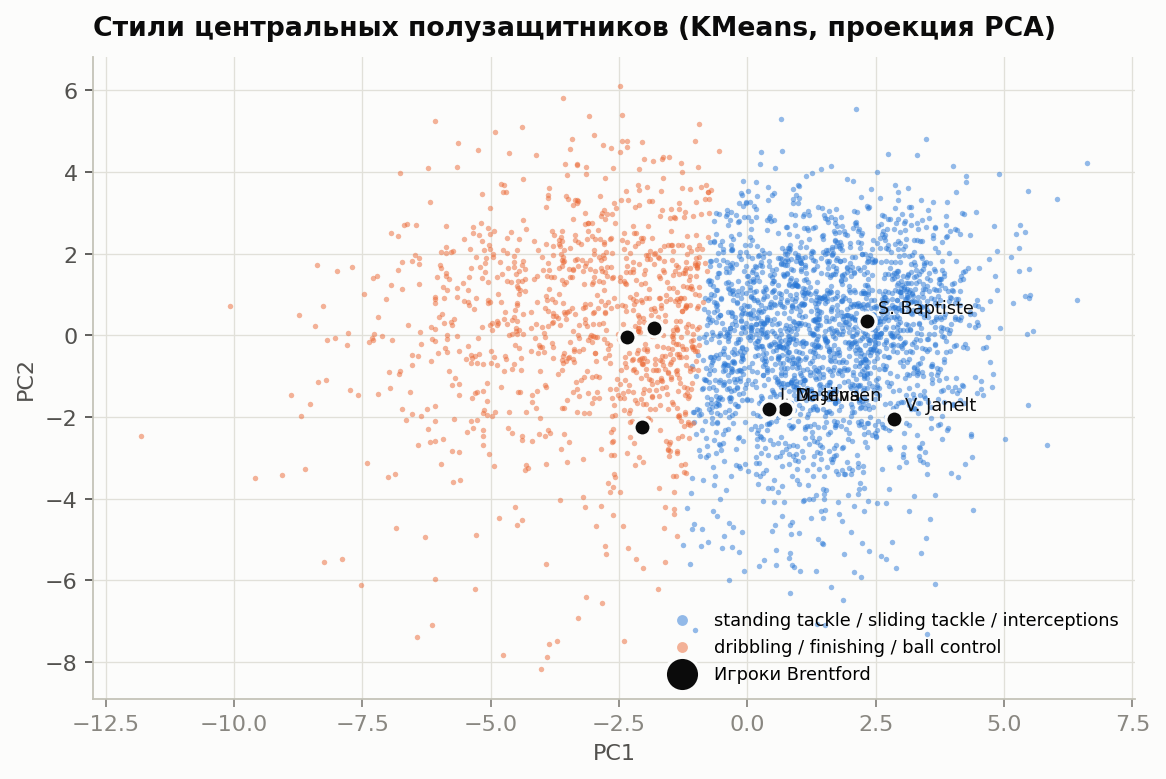

In [15]:
img("10_clusters_cm.png")

In [16]:
pd.read_csv(OUT / 'similarity_eval.csv', index_col=0).round(3)

,hit@1,hit@10,median_rank_pct,same_position,same_foot
method,,,,,
"Стиль (cosine, наш метод)",0.847,0.910,0.000,0.596,0.646
Сырые атрибуты (cosine),0.824,0.891,0.000,0.583,0.648
Ближайший overall,0.007,0.047,8.272,0.526,0.635
Случайно,0.001,0.004,49.967,0.521,0.634


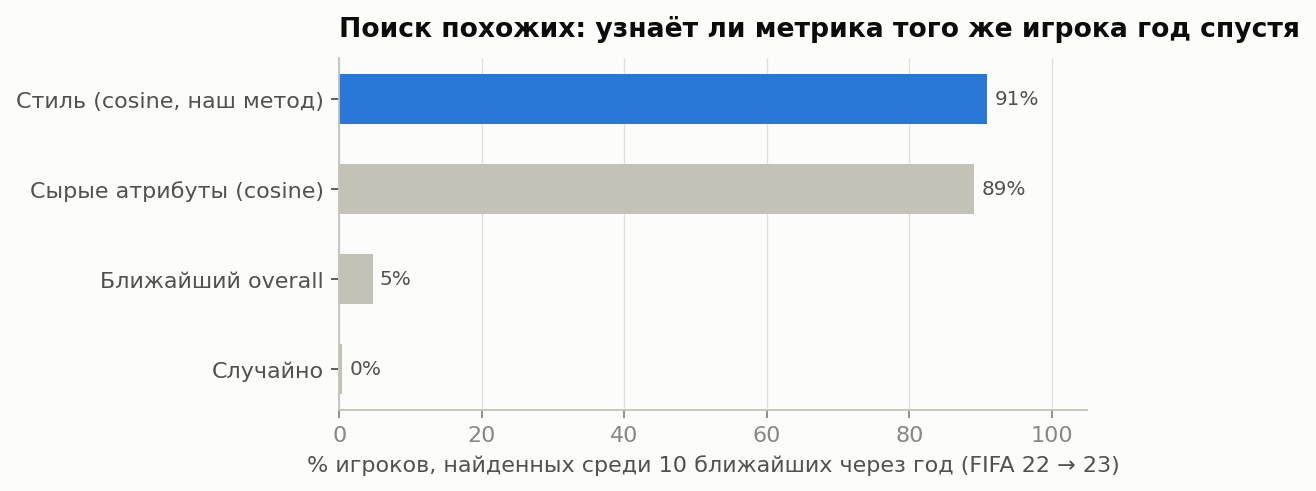

In [17]:
img("11_similarity_reid.png")

**Проверка «похожести» без разметки (Re-ID).**
1. Берём профиль игрока в FIFA 22.
2. Ищем ближайших в FIFA 23 и смотрим, найдётся ли **тот же игрок**.

Результат: стиль-вектор находит его в топ-10 в **91%** случаев, ближайший overall — в 4.7%. Метод сравнивает именно стиль, а не «силу».

## 6. Переход в АПЛ

In [18]:
pd.read_csv(OUT / 'league_move_effect.csv').round(2)

,league_name,n,resid,delta
0,Premiership,20.0,-0.08,1.40
1,Super Lig,19.0,0.22,0.32
2,Bundesliga,97.0,0.25,0.82
3,(остались в лиге),3101.0,0.26,0.76
4,Eredivisie,49.0,0.43,1.41
5,La Liga,105.0,0.44,0.87
6,League Two,27.0,0.45,2.81
7,Liga Portugal,34.0,0.66,1.44
8,Jupiler Pro League,28.0,0.67,1.68
9,League One,62.0,0.80,2.55


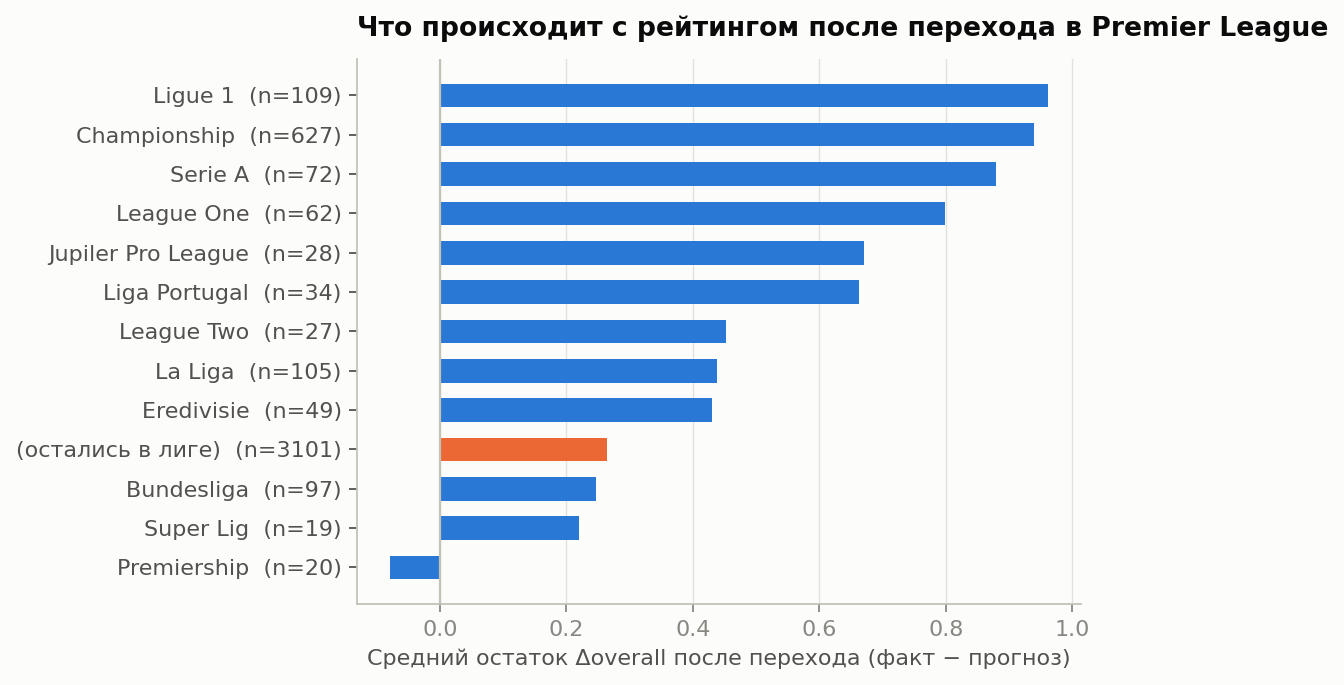

In [19]:
img("09_league_moves.png")

**Отрицательный результат, который мы честно показываем.** После перехода в АПЛ рейтинг не падает: остатки положительные.

Причина — **ошибка отбора**: в АПЛ переходят те, кто и так прогрессирует. Поправку на лигу мы *не* вводим, потому что данные её не подтверждают. Это записано как ограничение.

## 7. Решение: кандидаты, MCDA, оптимизация
Пул кандидатов задаётся правилами реалистичности:
* возраст ≤ 29;
* не в аренде;
* более сильный клуб (> +2 к среднему составу) не продаёт стартовых игроков;
* зарплата ≤ 2× максимальной в Брентфорде;
* **без лиг без лицензии** (ловушка 5).

Рейтинг для клуба считается как `0.6·overall + 0.4·fit_rating`. Ранжирование — WSM/TOPSIS с проверкой чувствительности весов (Dirichlet). Итоговый выбор делает MILP (`scipy.optimize.milp`).

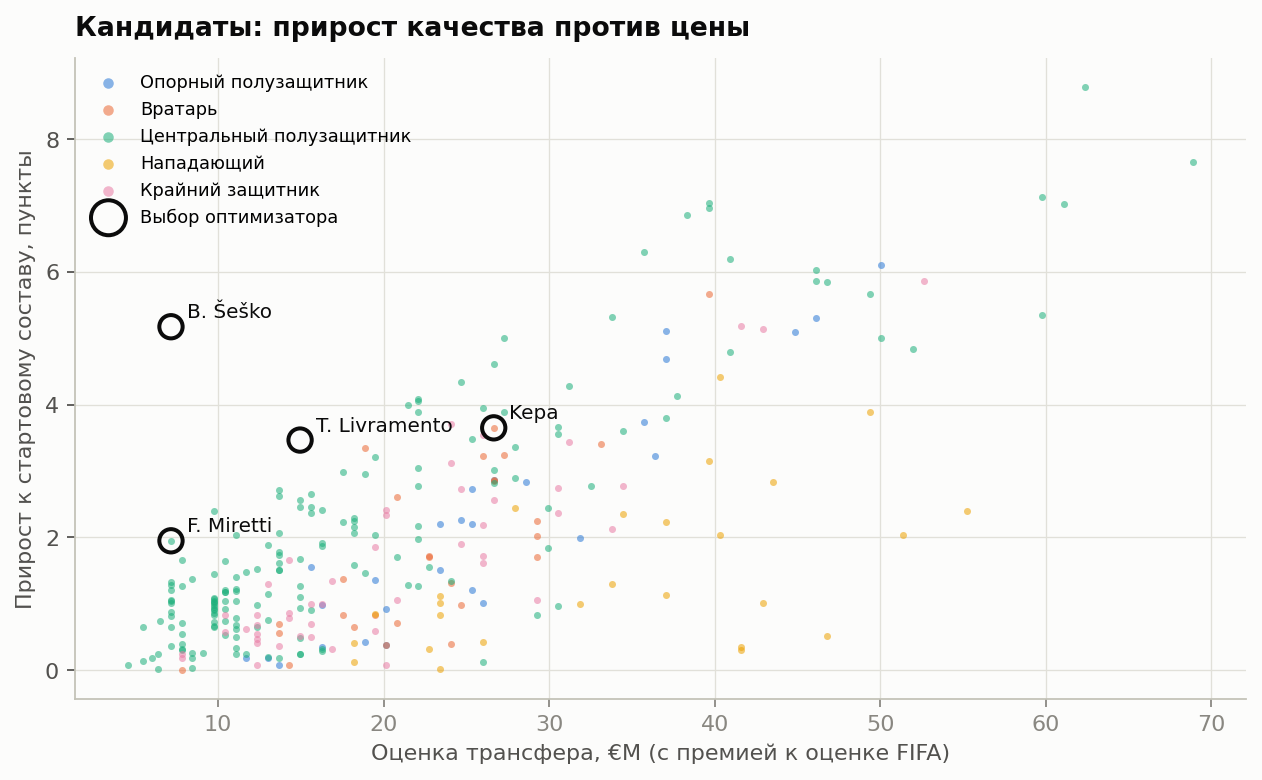

In [20]:
img("12_candidates.png")

In [21]:
plan = pd.read_csv(OUT / "transfer_plan.csv")
plan[["short_name", "club_name", "league_name", "group", "age", "overall", "fit_pct", "pred_delta",
      "p_decline", "fee", "wage_new", "gain", "net_value"]].round(2)

,short_name,club_name,league_name,group,age,overall,fit_pct,pred_delta,p_decline,fee,wage_new,gain,net_value
0,B. Šeško,Salzburg,Bundesliga (Austria),ST,19,72,78.66,2.65,0.06,7150000.0,25600.0,5.17,16788859.47
1,T. Livramento,Southampton,Premier League,FB,19,75,91.63,1.48,0.06,14950000.0,25600.0,3.47,11776256.79
2,F. Miretti,Juventus,Serie A,CM,18,72,89.78,3.11,0.04,7150000.0,25600.0,1.95,25354294.77
3,Kepa,Chelsea,Premier League,GK,27,80,98.93,-0.05,0.19,26650000.0,80000.0,3.65,-7452509.67


In [22]:
print(f"Потрачено: €{plan.fee.sum()/1e6:.1f}M из €{C.BUDGET_FEE_EUR/1e6:.0f}M; "
      f"новые зарплаты €{plan.wage_new.sum()/1e3:.0f}k/нед; прирост состава {plan.gain.sum():+.1f}")
pd.read_csv(OUT / "budget_scenarios.csv")[["budget_share", "players", "fee", "gain"]].round(2)

Потрачено: €55.9M из €60M; новые зарплаты €157k/нед; прирост состава +14.2


,budget_share,players,fee,gain
0,0.5,"B. Šeško (ST), T. Livramento (FB), F. Miretti ...",29250000.0,10.59
1,0.8,"B. Šeško (ST), J. Sánchez (FB), F. Miretti (CM...",47450000.0,14.51
2,1.0,"B. Šeško (ST), T. Livramento (FB), F. Miretti ...",55900000.0,14.24
3,1.2,"B. Šeško (ST), A. Onana (GK), T. Livramento (F...",68900000.0,16.25


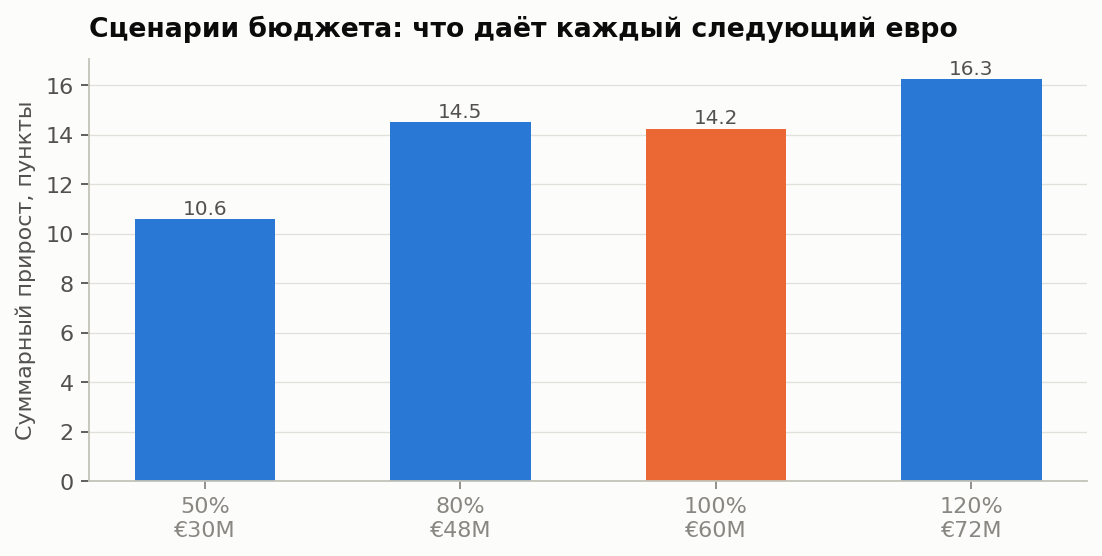

In [23]:
img("13_budget_scenarios.png")

In [24]:
pd.read_csv(OUT / 'weight_sensitivity.csv').groupby('need').head(3)

,need,Unnamed: 1,short_name,club_name,age,overall,fee,top5_share
0,DM,348,I. Sangaré,PSV,24,81,46150000.0,0.853333
1,DM,334,Palhinha,Fulham,26,81,37050000.0,0.763333
2,DM,324,L. Torreira,Galatasaray,26,81,37050000.0,0.700000
10,GK,250,A. Onana,Inter,26,82,39650000.0,0.880000
11,GK,464,A. Lafont,Nantes,23,80,33150000.0,0.880000
12,GK,410,Kepa,Chelsea,27,80,26650000.0,0.800000
20,CM,222,Sergi Darder,Espanyol,28,82,39650000.0,0.636667
21,CM,661,Gavi,FC Barcelona,17,79,46800000.0,0.613333
22,CM,3553,F. Miretti,Juventus,18,72,7150000.0,0.466667
30,ST,228,S. Haller,Borussia Dortmund,28,82,40300000.0,0.943333


In [25]:
pd.read_csv(OUT / 'hidden_gems.csv')[['short_name','club_name','league_name','group','age','overall','fit_pct','fee']]

,short_name,club_name,league_name,group,age,overall,fit_pct,fee
0,D. de Wit,AZ,Eredivisie,CM,24,74,97.962334,7800000.0
1,M. Thorsby,FC Union Berlin,Bundesliga,CM,26,74,94.319234,6500000.0
2,H. Hajradinović,Kasımpaşa,Super Lig,CM,28,74,95.307194,5460000.0
3,R. Zalazar,Schalke 04,Bundesliga,CM,22,73,92.929917,7800000.0
4,M. Pedersen,Feyenoord,Eredivisie,FB,22,74,97.720313,11700000.0
5,M. Schwäbe,FC Köln,Bundesliga,GK,27,77,96.923828,13650000.0
6,J. Brownhill,Burnley,Championship,CM,26,75,95.986416,9750000.0
7,L. O'Brien,Nottingham Forest,Premier League,CM,23,73,92.188947,7800000.0
8,Fran García,Rayo Vallecano,La Liga,FB,22,75,96.699558,15600000.0
9,Robert Sánchez,Brighton & Hove Albion,Premier League,GK,24,77,96.826172,17550000.0


In [26]:
sq = pd.read_csv(OUT / "squad.csv")
sq[sq.action != "Оставить"][["short_name", "group", "age", "overall", "role", "action", "reason"]]

,short_name,group,age,overall,role,action,reason
2,M. Cox,GK,19,60,резерв,Аренда для развития,"потенциал +17, нужен игровой опыт"
6,P. Jansson,CB,31,75,резерв,Продать / не продлевать,"31 лет, контракт до 2023: стоимость ещё есть, ..."
7,Zanka,CB,32,72,резерв,Продать / не продлевать,"32 лет, контракт до 2023: стоимость ещё есть, ..."
9,T. Crama,CB,20,58,резерв,Аренда для развития,"потенциал +13, нужен игровой опыт"
20,Y. Yarmoliuk,CM,18,62,резерв,Аренда для развития,"потенциал +18, нужен игровой опыт"
21,R. Trevitt,CM,19,58,резерв,Аренда для развития,"потенциал +15, нужен игровой опыт"
25,K. Lewis-Potter,W,21,71,резерв,Аренда для развития,"потенциал +9, нужен игровой опыт"
27,A. Gilbert,W,20,59,резерв,Аренда для развития,"потенциал +11, нужен игровой опыт"
29,A. Pressley,ST,20,61,ротация,Аренда для развития,"потенциал +13, нужен игровой опыт"


**Решение.** Покупки:

| Игрок | Позиция | Почему |
|---|---|---|
| Шешко | ST | дублёр и наследник Тони, рост +2.7 |
| Ливраменто | FB | 19 лет, fit 92-й перцентиль |
| Миретти | CM | 18 лет, лучший прогноз роста |
| Кепа | GK | +7 к уровню вратаря |

Итого €55.9M.

Сценарии бюджета показывают **устойчивое ядро**: Шешко + Миретти + крайний защитник есть в каждом сценарии от 50% до 120% бюджета. Вратарь зависит от денег.

Продажи (правила): Янссон, Занка. Аренды: молодые резервисты.

## 8. Ловушки футбольной аналитики — проверка в коде

In [27]:
df = pd.read_parquet(C.DATA_CACHE)
raw = pd.read_csv(C.DATA_RAW, usecols=["fifa_version", "league_name", "league_id", "club_name"], low_memory=False)
pl = raw[(raw.fifa_version == 23) & (raw.league_name == "Premier League")]
print("Ловушка 3. Клубов с league_name='Premier League' в FIFA 23 (до очистки):", pl.club_name.nunique())
print(pl.groupby("league_id").club_name.nunique().rename("клубов").to_string())

Ловушка 3. Клубов с league_name='Premier League' в FIFA 23 (до очистки): 25
league_id
13.0     20
332.0     2
347.0     3


In [28]:
br = df[(df.fifa_version == 23) & (df.league_name == "Serie A (Brazil)")].nlargest(6, "overall")
print("Ловушка 5. Топ бразильской Серии A в FIFA 23 — вымышленные имена (нет лицензии EA):")
br[["short_name", "club_name", "overall"]]

Ловушка 5. Топ бразильской Серии A в FIFA 23 — вымышленные имена (нет лицензии EA):


,short_name,club_name,overall
141257,Ronaldo Cabrais,Palmeiras,83
141330,Lucas Mantela,Palmeiras,82
141331,Josué Chiamulera,Athletico PR,82
141411,Heberto Gaúcho,Atlético Mineiro,81
141412,Adryan Zonta,Bragantino,81
141413,Rosival Dourado,Corinthians,81


| # | Ловушка | Как проявилась | Что сделали |
|---|---|---|---|
| 1 | **Утечка будущего** | случайный split смешивает FIFA 23 в train и FIFA 22 в test | split строго по версиям; prev_delta берётся только из прошлого |
| 2 | **Рейтинги ≠ реальная игра** | FIFA — экспертная оценка EA, не xG/минуты | вывод — «шорт-лист для скаутов», а не автопокупка; ЛПР проверяет видео |
| 3 | **Коллизия названий** | «Premier League» — это 4 разные лиги (Англия, Россия, Украина, ЮАР); в FIFA 23 у лиги 25 клубов вместо 20 | разведение по league_id |
| 4 | **Цена — формула** | R² 0.999 | не ищем «недооценённых» по остатку; премия АПЛ; бюджет — допущение |
| 5 | **Нелицензированные лиги** | «Ronaldo Cabrais» — топ Палмейраса | исключены из покупок, оставлены в обучении |
| 6 | **Ошибка отбора** | переход в АПЛ «улучшает» рейтинг | не вводим поправку, называем ограничением |
| 7 | **Позиционная несравнимость** | overall вратаря ≠ overall вингера | все сравнения внутри позиционной группы |

## 9. Ограничения
* FIFA — прокси реальной силы, обновляется с запаздыванием.
* Нет минут, травм, xG и желания игрока переходить.
* Бюджет, премия и зарплатная политика — допущения. В DSS они вынесены в слайдеры.
* Оценка эффекта плана — только по модели. Ретро-проверка на реальных трансферах 2023–2025 — качественная, см. README.

## Тот же пайплайн для Ливерпуля и ПСЖ

Клуб — это параметр (`config.CLUBS`, запуск `python run_pipeline.py --club liverpool|psg`). У клубов разные цели:

| Клуб | Ориентир по позициям | Бюджет | Зарплаты/нед |
|---|---|---|---|
| Брентфорд | 6-й клуб АПЛ | €60M | €200k |
| Ливерпуль | лучший соперник в АПЛ (Ман Сити) | €150M | €1.0M |
| ПСЖ | 3-й клуб топ-5 лиг Европы (в Лиге 1 конкурентов нет) | €200M | €1.5M |

**Найденная ловушка №8:** «Liverpool» в FIFA — это и английский, и уругвайский клуб. Без разведения одноимённых клубов в состав «Ливерпуля» попадали уругвайцы.

In [29]:
rows = []
for k in ["brentford", "liverpool", "psg"]:
    o = C.ROOT / "outputs" / k
    n = pd.read_csv(o / "needs.csv").head(3)
    p = pd.read_csv(o / "transfer_plan.csv")
    rows.append({"клуб": C.CLUBS[k]["name"],
                 "главные дыры": ", ".join(f"{g} ({x:.1f})" for g, x in zip(n.group, n.gap)),
                 "план": ", ".join(f"{a} ({g})" for a, g in zip(p.short_name, p.group)),
                 "цена, €M": round(p.fee.sum() / 1e6, 1), "прирост": round(p.gain.sum(), 1)})
pd.DataFrame(rows)

,клуб,главные дыры,план,"цена, €M",прирост
0,Брентфорд,"DM (7.6), GK (7.4), CM (7.2)","B. Šeško (ST), T. Livramento (FB), F. Miretti ...",55.9,14.2
1,Ливерпуль,"ST (5.0), CM (3.9), DM (1.6)","A. Elanga (W), A. Davies (FB), R. De Paul (CM)",145.6,11.1
2,ПСЖ,"DM (8.3), GK (2.3), FB (1.9)","S. Tonali (DM), A. Davies (FB), G. Laborde (ST)",194.4,11.2


**Вывод.**
- **Брентфорд.** Самый эффективный рынок — молодые игроки с прогнозом роста: €56M дают +14 пунктов.
- **Ливерпуль.** Главные дыры (ST, CM, DM) закрываются только звёздами за €100M+, у которых маленький прирост на евро. Без ограничения «закрыть хотя бы одну главную дыру» оптимизатор покупал бы только дублёров. С ограничением выбирает Де Пауля в центр поля; при другом бюджете — Беллингема.
- **ПСЖ.** Явная дыра — опорная зона: 27-е место среди клубов топ-5 лиг. Первым выбором при любом бюджете стоит Тонали.
- **Общее.** Чем сильнее клуб, тем дороже каждый пункт прироста: €4M за пункт у Брентфорда против €13–17M у Ливерпуля и ПСЖ.